<a href="https://colab.research.google.com/github/aufaa-ds/Tugas-Data-Wrangling/blob/main/Data_Wrangling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Nama Anggota Kelompok**
1. Muhammad Alvian Alpha Romeo (25031554080)
2. Aufaa Luthfiyyah Zaahidah (25031554098)
3. Faris Riky Pratama (25031554176)

# **Import Depedencies & Load Dataset**

In [ ]:
!pip install sweetviz imbalanced-learn seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sweetviz as sv
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, roc_auc_score, recall_score, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
           'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

In [ ]:
path = '/content/drive/MyDrive/Dataset/pima-indians-diabetes.csv'
df = pd.read_csv(path, header=None, names=columns)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# **Data Understanding (Fitur-Fitur)**

Variabel Independen (X) :

- Pregnancies : Number of times pregnant (mempresentasikan berapa kali wanita tersebut hamil selama hidupnya)
- Glucose: Plasma glucose concentration a 2 hours in an oral glucose tolerance test (mempresentasikan konsentrasi glukosa plasma pada 2 jam dalam tes toleransi glukosa).
- Blood Pressure: Diastolic blood pressure (Tekanan darah adalah cara yang sangat terkenal untuk mengukur kesehatan jantung seseorang, ada juga ukuran tekanan darah yaitu diastolik dan sistolik. Dalam data ini, kita memiliki tekanan darah diastolik dalam (mm / Hg) ketika jantung rileks setelah kontraksi).
- Skin Thickness: Triceps skin fold thickness (nilai yang digunakan untuk memperkirakan lemak tubuh (mm) yang diukur pada lengan kanan setengah antara proses olecranon dari siku dan proses akromial skapula).
- Insulin: 2-Hour serum insulin (tingkat insulin 2 jam insulin serum dalam satuan mu U/ml)
- BMI: Body mass index (Indeks Massa Tubuh (berat dalam kg / (tinggi dalam meter kuadrat), dan merupakan indikator kesehatan seseorang).
- Diabetes Pedigree Function: Diabetes pedigree function (indikator riwayat diabetes dalam keluarga)
- Age: umur wanita suku indian pima (years)

Variabel Dependen (Y) :

Outcome: Class variable (0 or 1), 0 untuk tidak mengidap diabetes, dan 1 mengidap diabetes.

In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
for i in df['Outcome'].unique():
    jumlah_cat = (df['Outcome'] == i).sum()
    jumlah_record = df.shape[0]
    persentase = jumlah_cat / jumlah_record * 100
    print(f"Jumlah {('Positive' if i == 1 else 'Negative')} Diabetes: {persentase:.2f}%")

Jumlah Positive Diabetes: 34.90%
Jumlah Negative Diabetes: 65.10%


# **Exploratory Data Analysis (EDA)**

EDA bertujuan untuk memahami karakteristik, distribusi, serta menemukan keanehan pada dataset Pima Indians Diabetes sebelum dilakukan tahap preprocessing dan pemodelan.

**Informasi Umum Dataset:**
   * Total data terdiri dari 768 baris dan 9 kolom (fitur).
   * Tidak ditemukan adanya data duplikat.
   * Terdapat 8 fitur numerik dan 1 fitur target/kategori.

**Indikasi *Missing Values* Implisit (Angka `0` yang Tidak Wajar):**
   Meskipun Sweetviz mencatat *missing values* secara sistem = 0%, grafik distribusi menunjukkan adanya angka `0` pada variabel fisiologis yang secara medis tidak mungkin:
   * **`Insulin`:** Memiliki angka `0` terbanyak, yaitu **374 data (49%)**.
   * **`SkinThickness`:** Memiliki angka `0` sebanyak **227 data (30%)**.
   * **`BMI`:** Memiliki angka `0` sebanyak **11 data (1%)**.
   * **`BloodPressure`:** Memiliki angka `0` sebanyak **35 data (5%)**.
   * **`Glucose`:** Memiliki angka `0` sebanyak **5 data (<1%)**.
   
  Angka `0` tersebut merupakan *missing values* terselubung yang wajib diganti menjadi `NaN` lalu diimputasi (misal dengan `IterativeImputer`, `Mean`, `Median`).

**Ketidakseimbangan Kelas Target:**
   * **Kelas `0` (Non-Diabetes):** 65.1% (sekitar 500 pasien).
   * **Kelas `1` (Diabetes):** 34.9% (sekitar 268 pasien).

**Karakteristik & Distribusi Umur (`Age`):**
   * Distribusi umur miring ke kanan (*right-skewed*), di mana sebagian besar sampel didominasi oleh kelompok usia muda (21–30 tahun).

                                             |          | [  0%]   00:00 -> (? left)


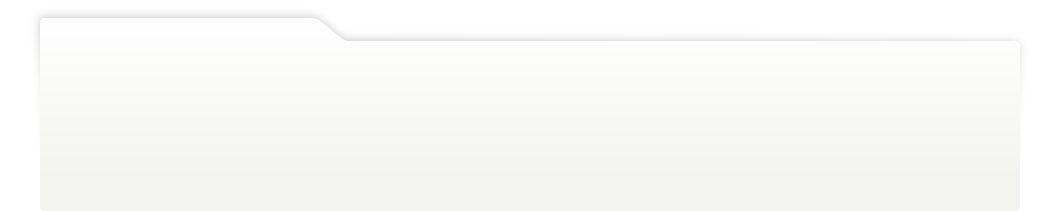
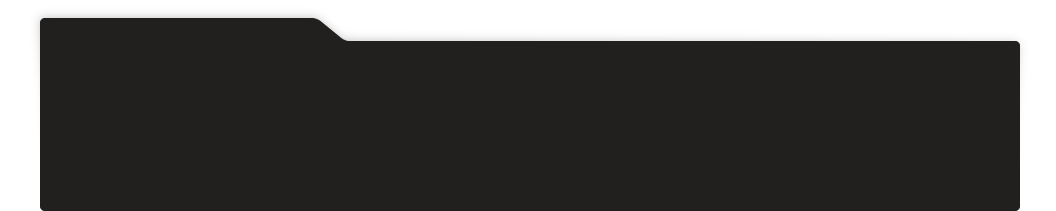
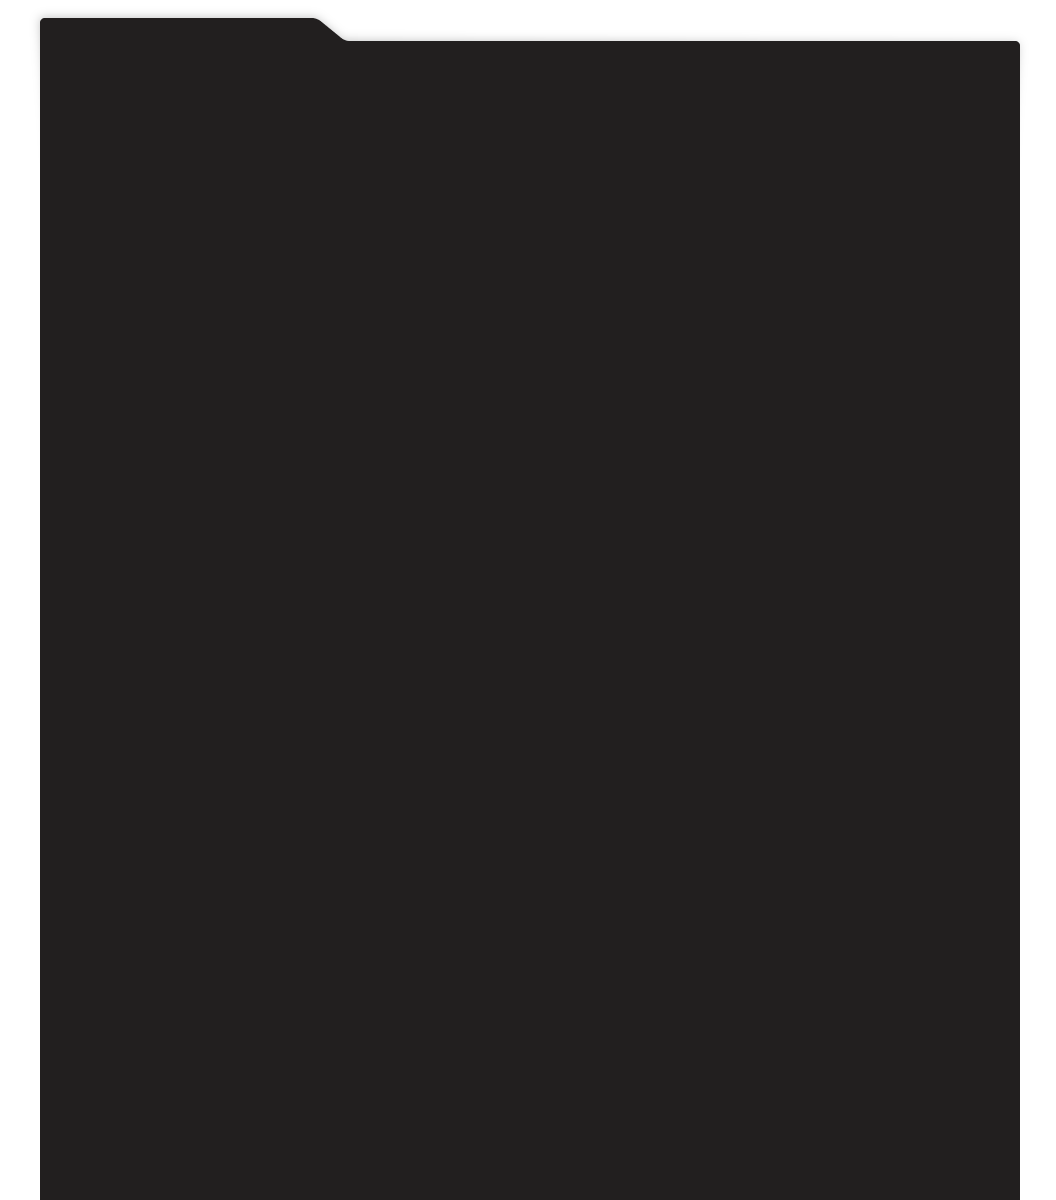
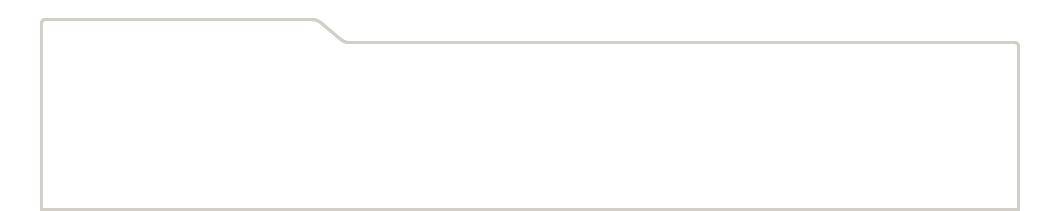
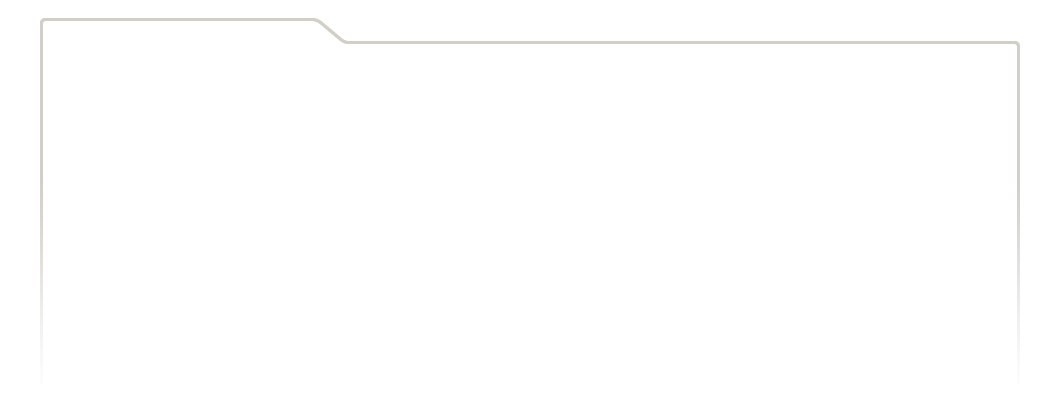
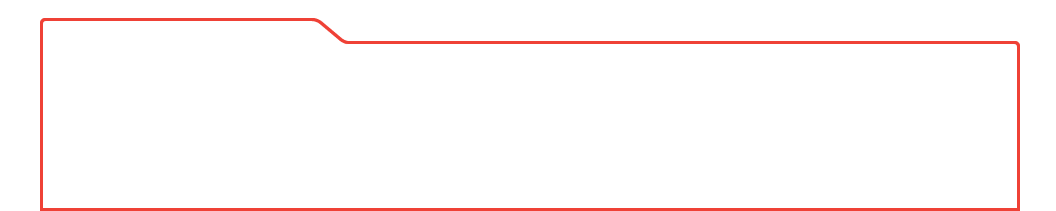
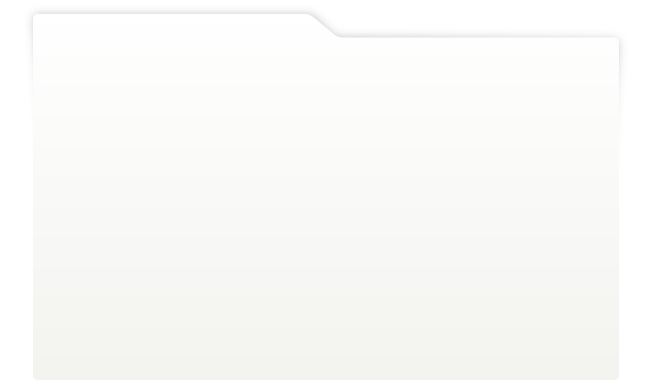
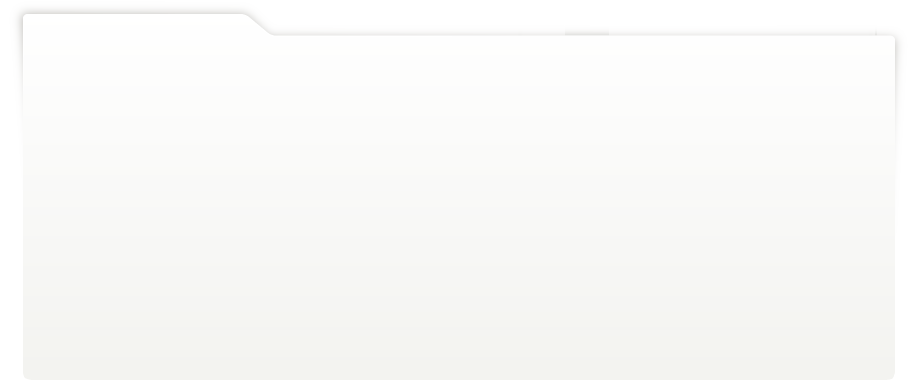
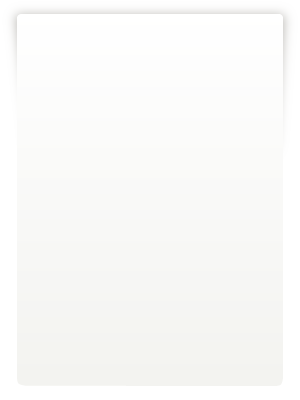
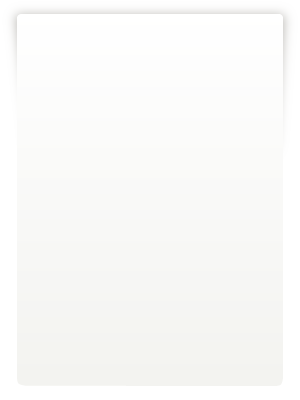
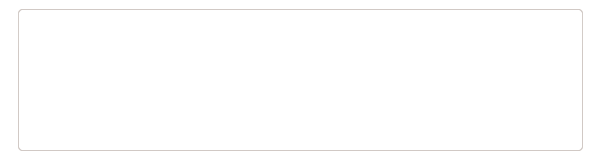
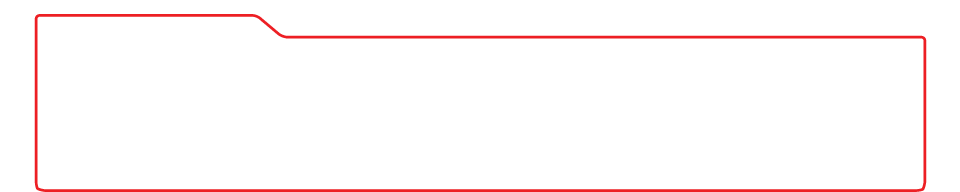
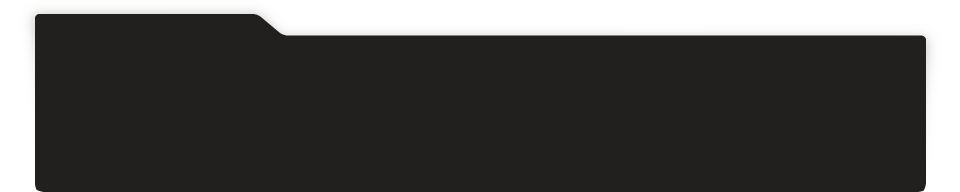
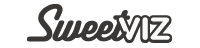
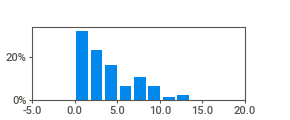
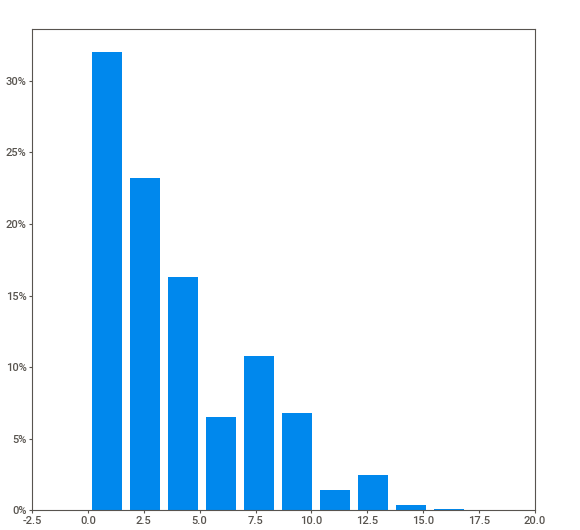
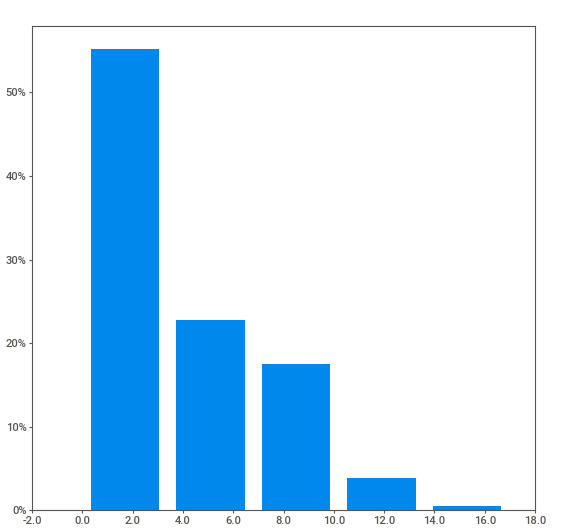
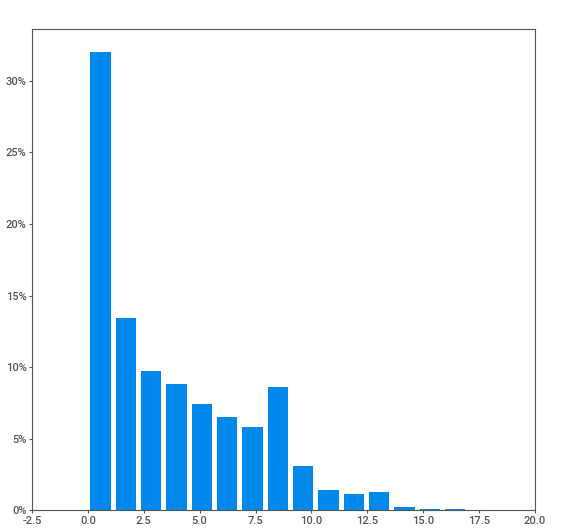
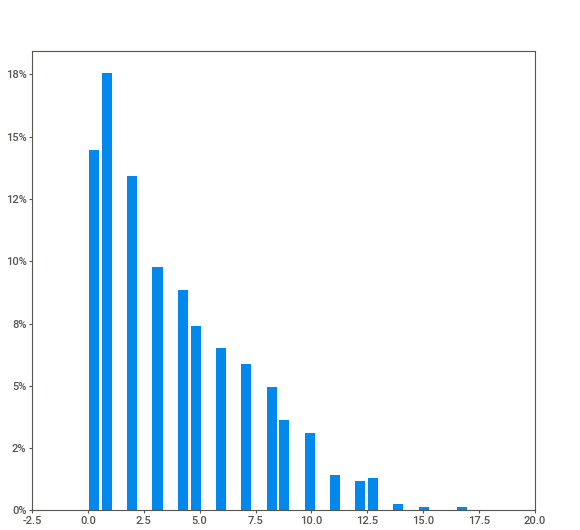
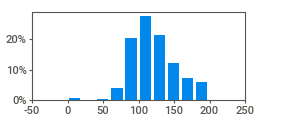
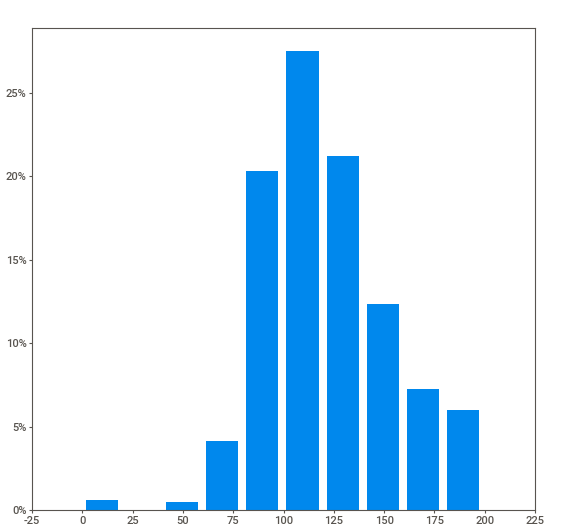
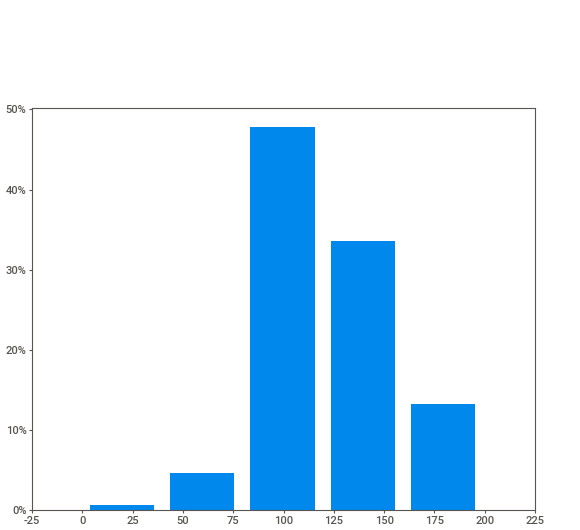
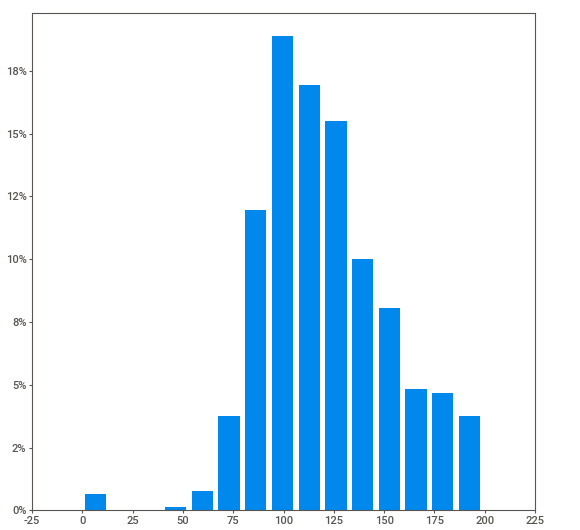
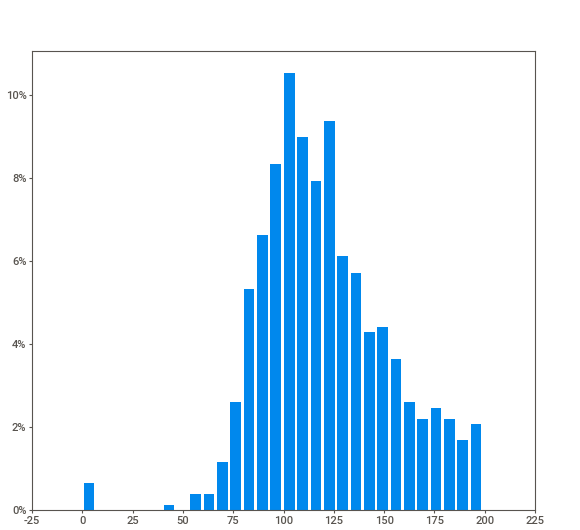
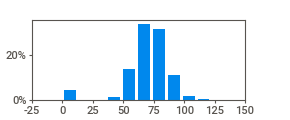
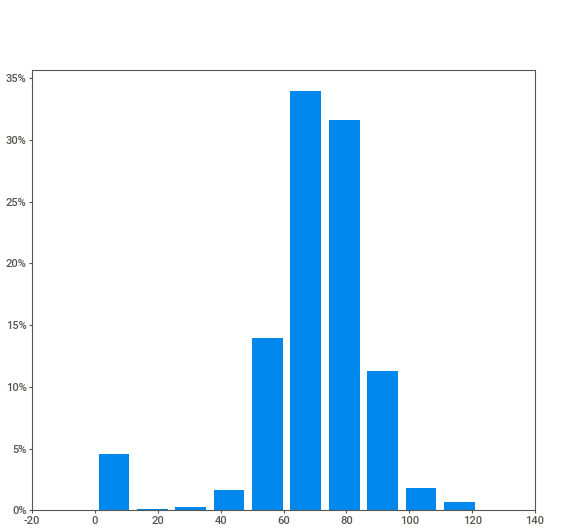
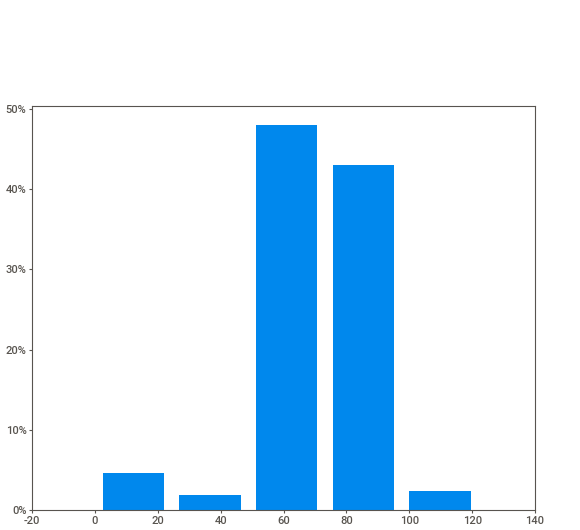
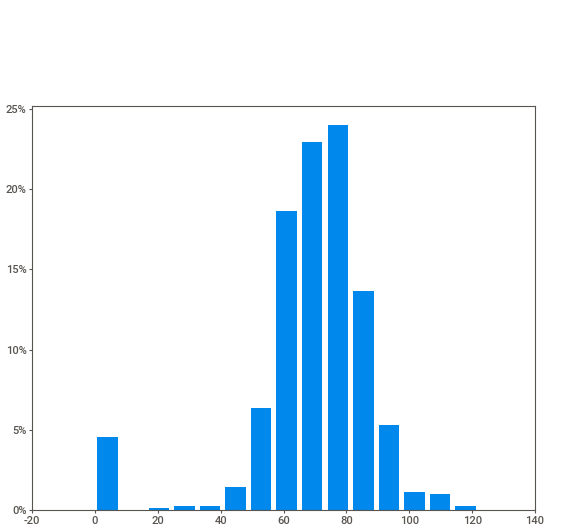
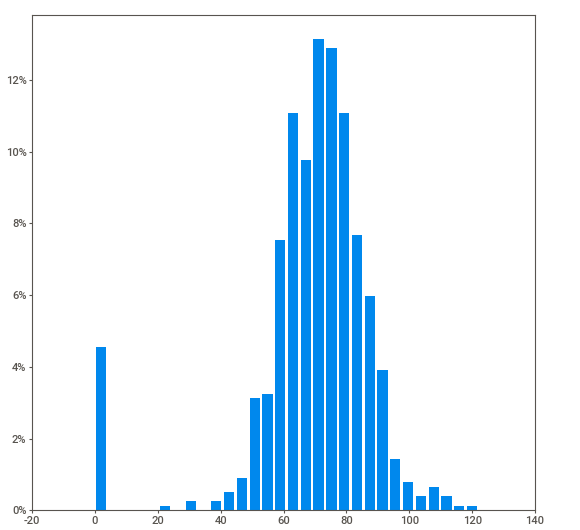
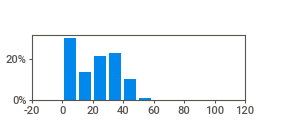
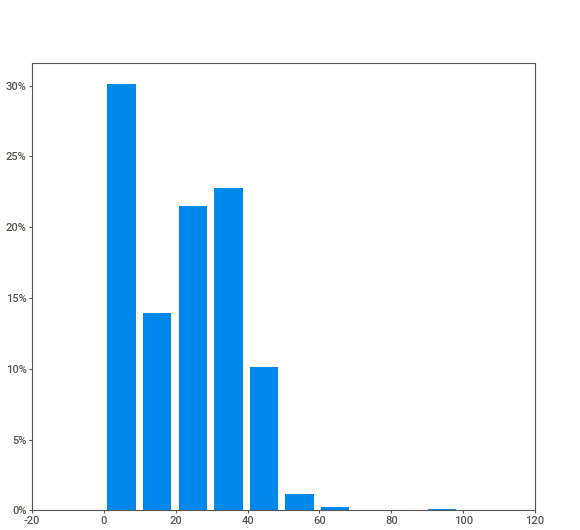
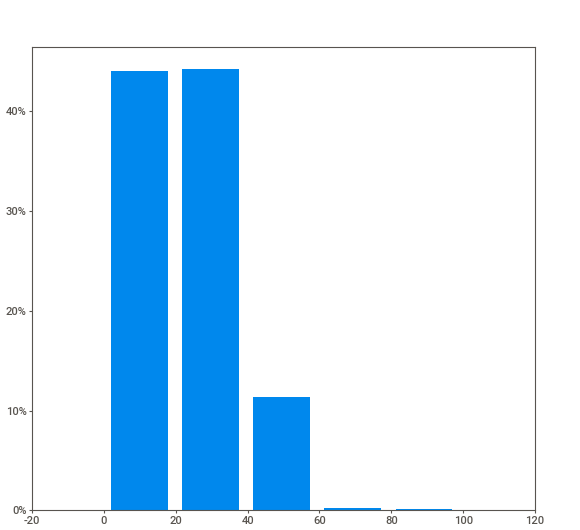
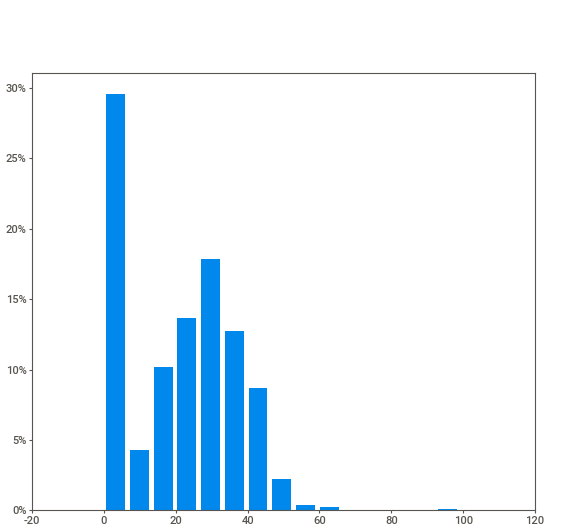
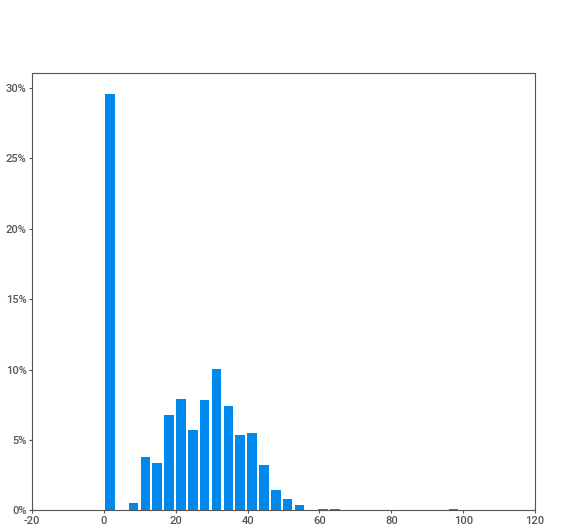
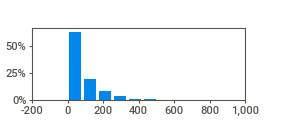
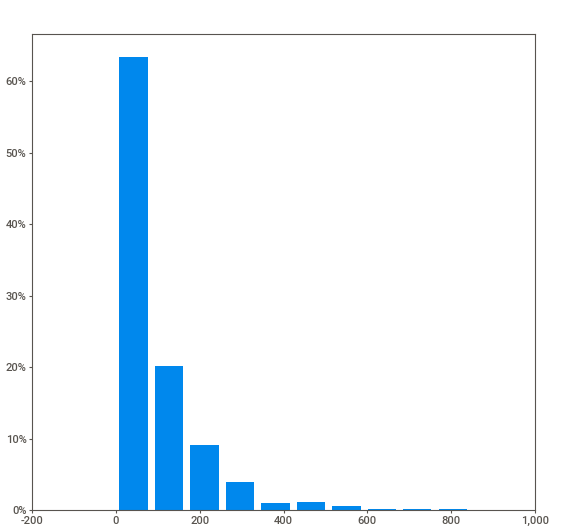
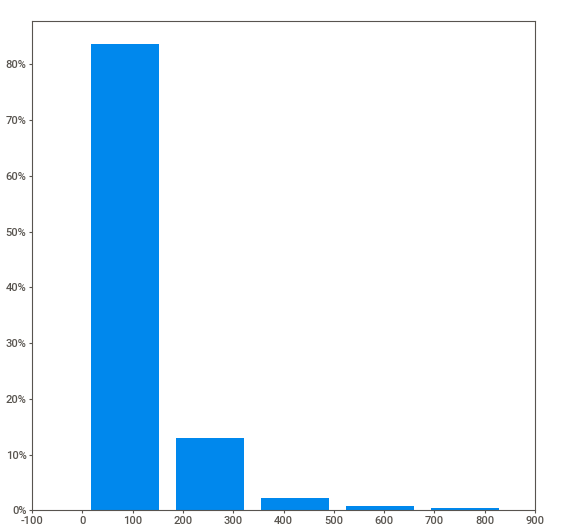
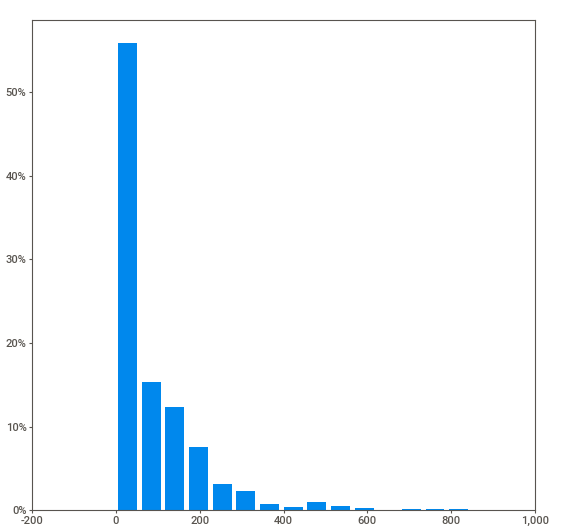
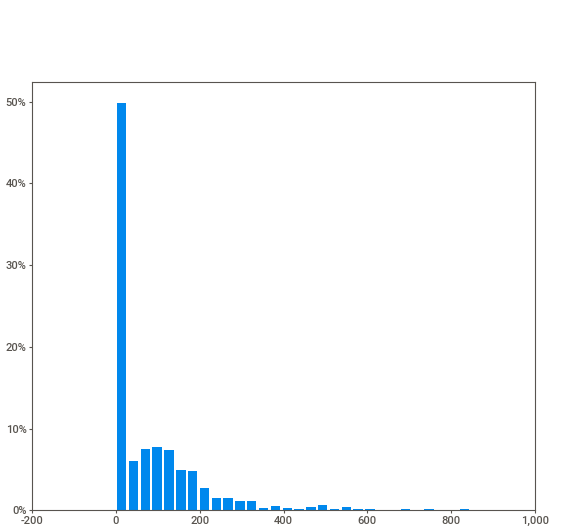
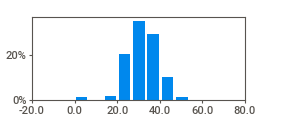
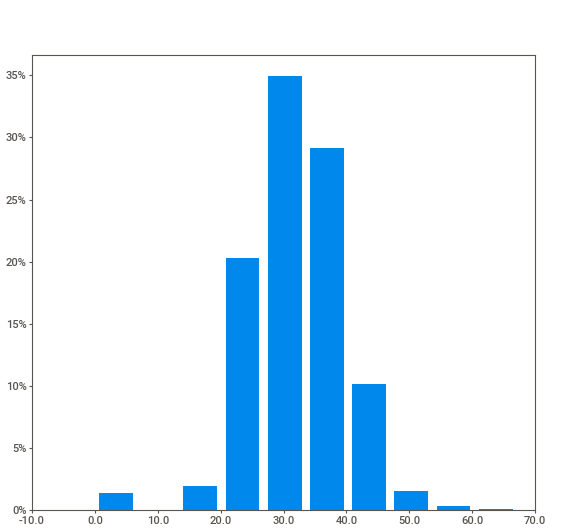
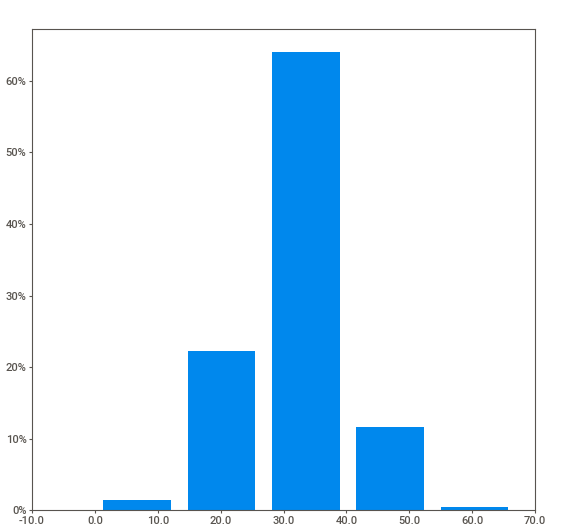
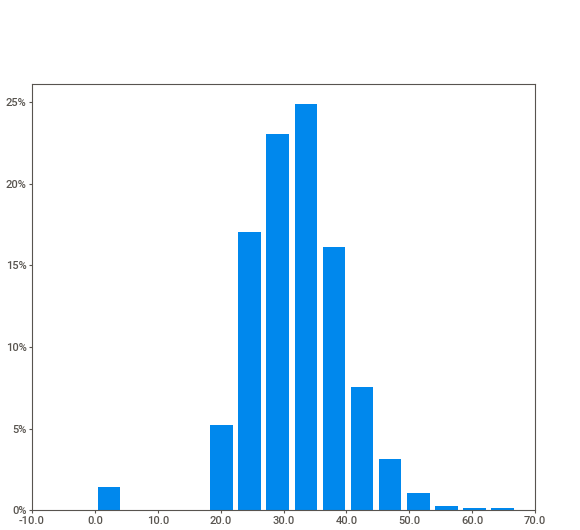
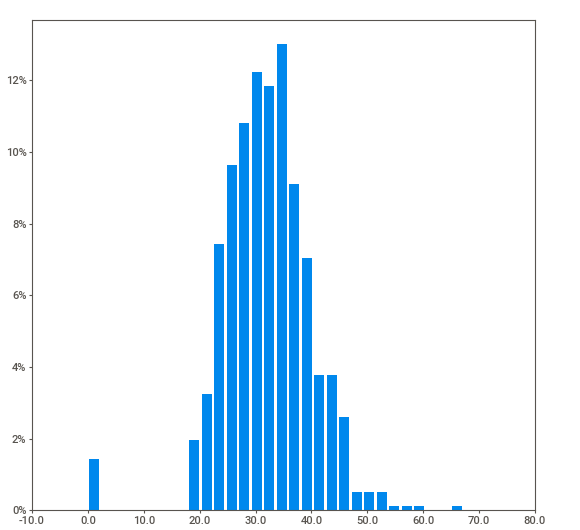
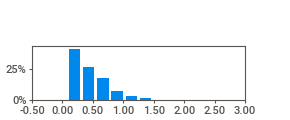
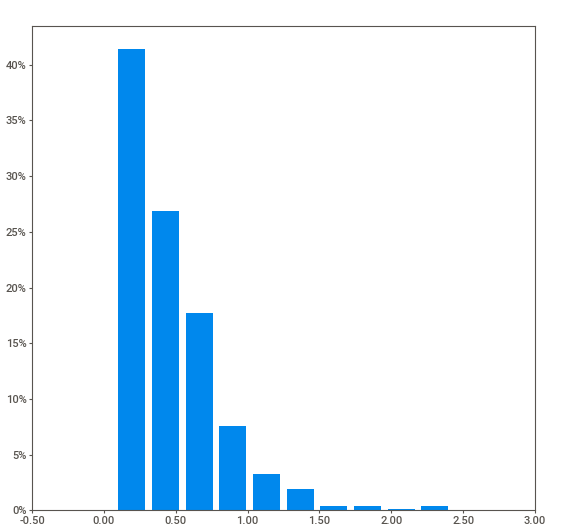
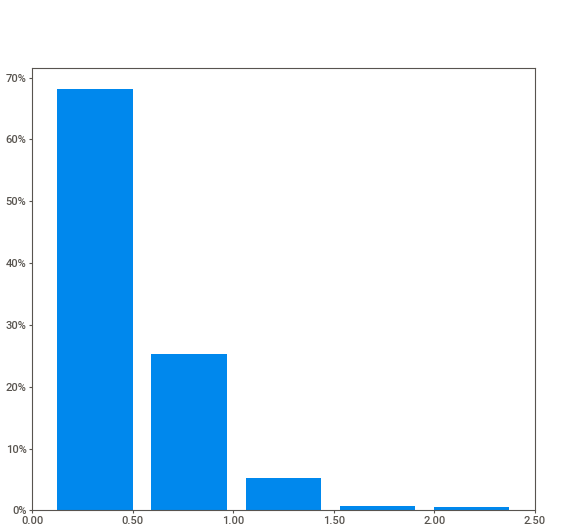
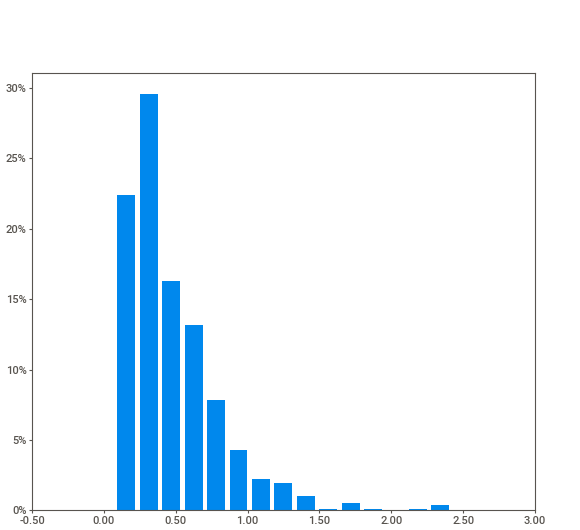
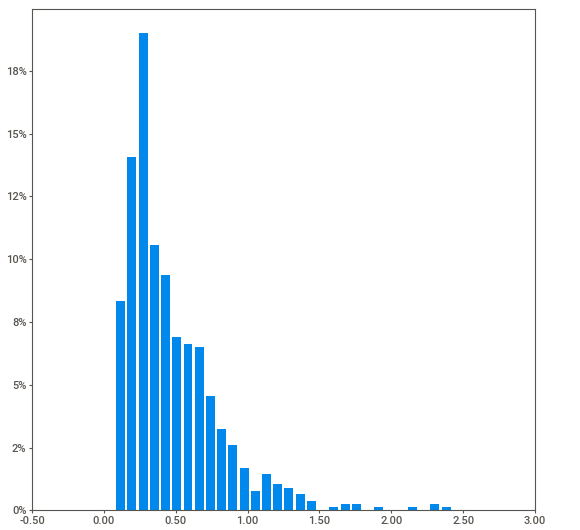
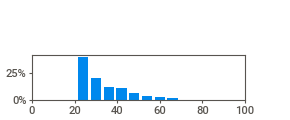
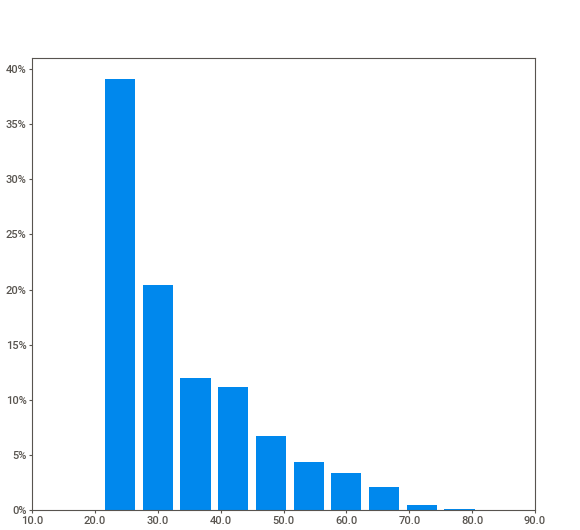
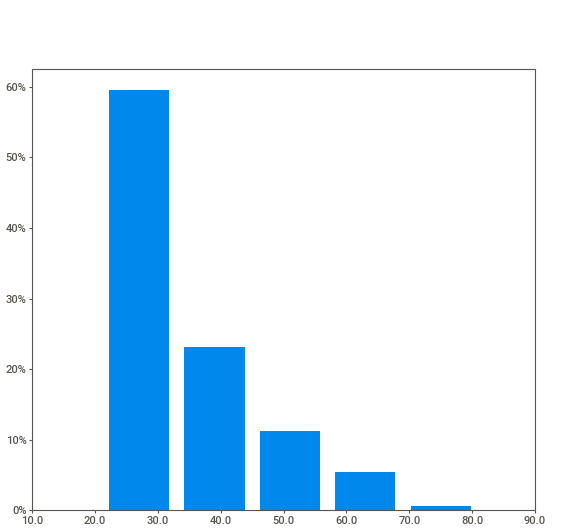
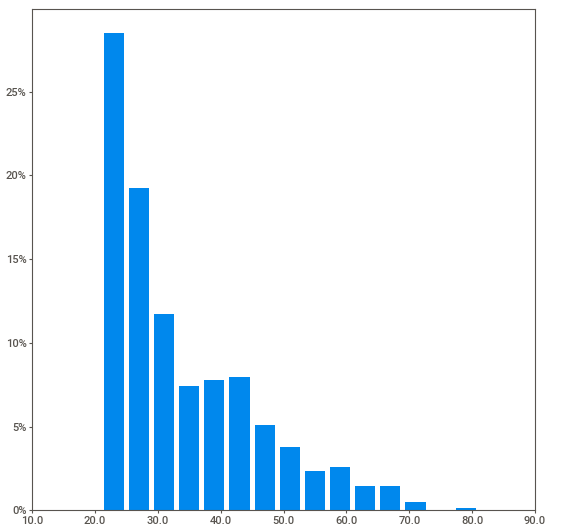
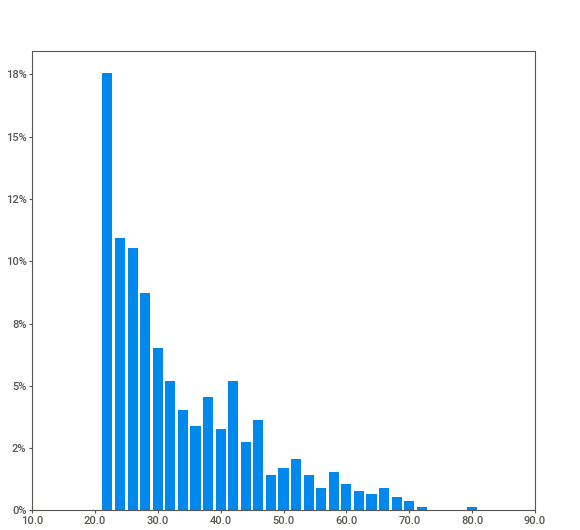
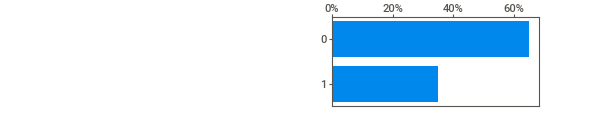
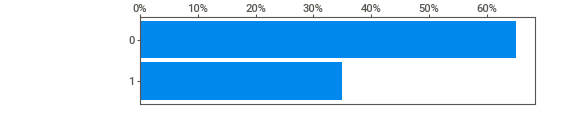
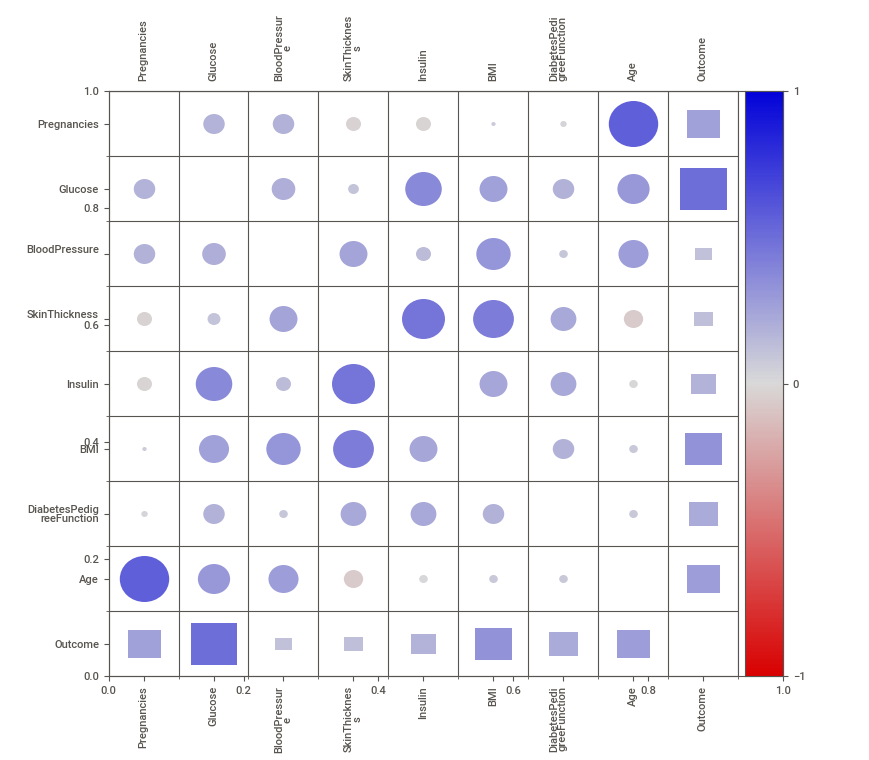
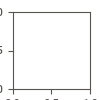

In [ ]:
report = sv.analyze(df)
report.show_notebook()

# **Data Quality**
Pada tahapan ini dilakukan pengecekan kualitas data terutama pada kolom Glukosa, BloodPressure, SkinThickness, Insulin, dan juga BMI. Data ini tidak memiliki missing value, tetapi pada kolom tersebut memiliki nilai 0 yang secara medis tidak mungkin. Namun, pada kolom pregnacies jika memiliki nilai 0 maka menadakan belum pernah hamil sebelumnya.

In [ ]:
# cek jumlah nilai 0/missing value dalam kolom Glucose, BloodPressure, SkinThickness, Insulin, dan BMI
kolom_cek = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
           'BMI']

for col in kolom_cek:
  jumlah_nol = (df[col] == 0).sum()
  persen = jumlah_nol / len(df) * 100
  print(f"{col}: {jumlah_nol} baris: ({persen:.2f}%)")

Glucose: 5 baris: (0.65%)
BloodPressure: 35 baris: (4.56%)
SkinThickness: 227 baris: (29.56%)
Insulin: 374 baris: (48.70%)
BMI: 11 baris: (1.43%)


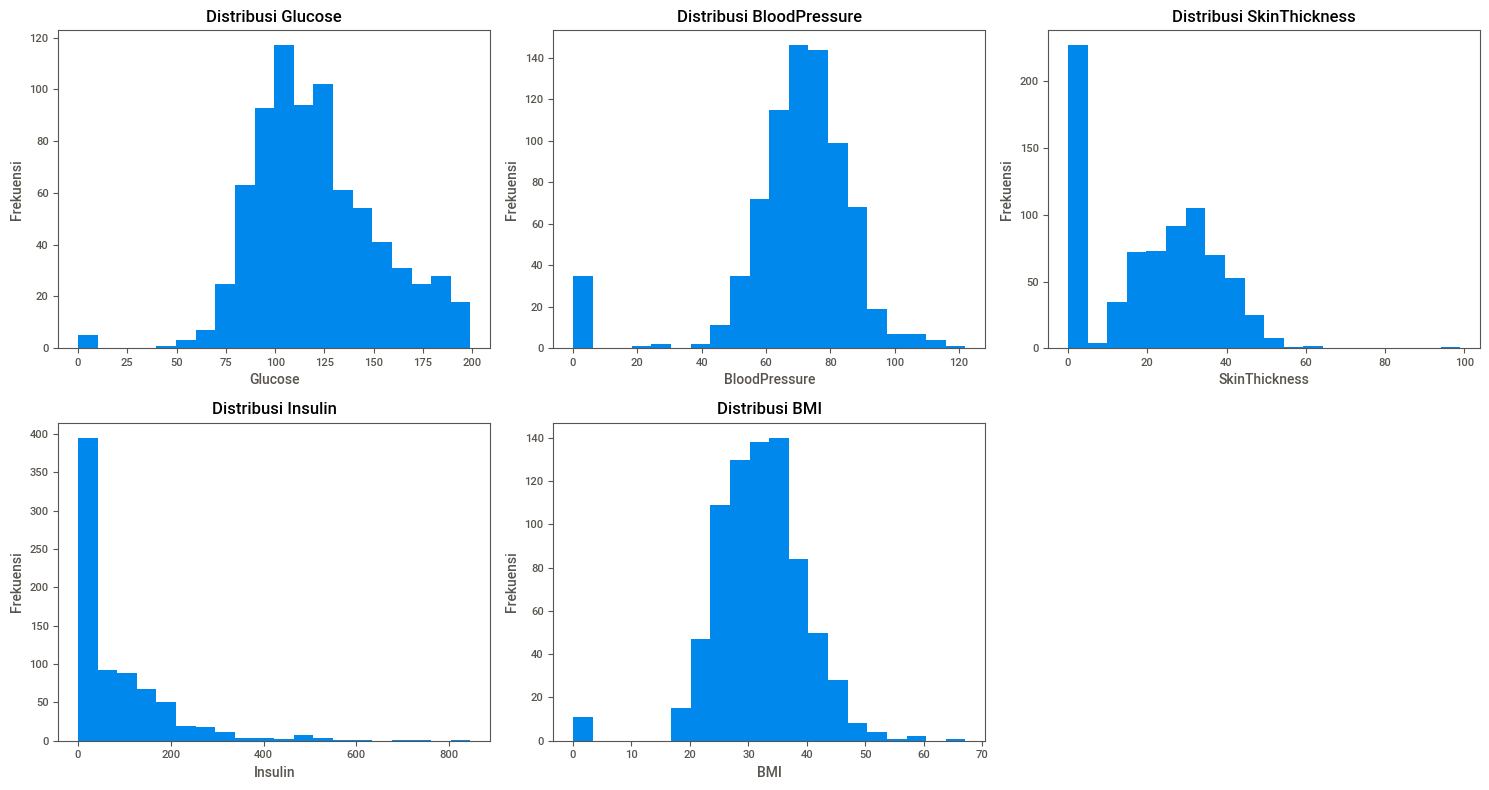

In [ ]:
# distribusi data
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_cek):
  axes[i].hist(df[col], bins=20)
  axes[i].set_title(f'Distribusi {col}')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Frekuensi')
  axes[5].set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_cek):
  axes[i].boxplot(df[col])
  axes[i].set_title(f'Distribusi {col}')
  axes[i].set_ylabel(col)
  axes[5].set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
# Identifikasi Outlier

for col in kolom_cek:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  jumlah_outlier = len(outliers)

  print(f"{col:20s}: {jumlah_outlier:3d} outlier (batas normal: {lower_bound:.2f} - {upper_bound:.2f})")

Glucose             :   5 outlier (batas normal: 37.12 - 202.12)
BloodPressure       :  45 outlier (batas normal: 35.00 - 107.00)
SkinThickness       :   1 outlier (batas normal: -48.00 - 80.00)
Insulin             :  34 outlier (batas normal: -190.88 - 318.12)
BMI                 :  19 outlier (batas normal: 13.35 - 50.55)


# **Eksperiment Preparation**
Pada tahap ini dibuat sebuah fungsi automation agar setiap kali model selesai dilatih, fungsi ini langsung menghitung metrik lengkapnya

In [ ]:
# fungsi metrik evaluasi
def evaluate(model, X_train, X_test, y_train, y_test, nama):
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)
  y_prob = model.predict_proba(X_test)[:, 1]

  tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

  sensitivity = tp / (tp + fn)
  specificity = tn / (tn + fp)

  results.append({
      'Eksperimen': nama,
      'Akurasi': accuracy_score(y_test, y_pred),
      'Balanced Accuracy': (sensitivity + specificity) / 2,
      'Sensitivity': sensitivity,
      'Specificity': specificity,
      'Precision': precision_score(y_test, y_pred),
      'Recall': recall_score(y_test, y_pred),
      'F1 Score': f1_score(y_test, y_pred),
      'ROC-AUC': roc_auc_score(y_test, y_prob)
  })

results = []

# **Base Model (Tanpa Preprocessing)**
Model Logistic Regression dilatih langsung pada data asli tanpa perbaikan apa pun. Nilai metrik dari base model ini dijadikan baseline (standar acuan) untuk melihat apakah perlakuan preprocessing di tahap selanjutnya mampu menaikkan performa model atau tidak.

In [ ]:
X = df.drop(columns='Outcome')
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2,
  random_state=42, stratify=y
)

evaluate(
  LogisticRegression(),
  X_train, X_test,
  y_train, y_test,
  'Tanpa Preprocessing'
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# **Eksperimen Imputation**
Pada tahap ini, data bermasalah (angka 0) diperbaiki menggunakan 3 teknik imputasi yang berbeda untuk membandingkan mana metode pengisian data yang terbaik.

1. **Mean Imputation:** Mengisi nilai hilang menggunakan rata-rata per kelompok kelas Outcome (diabetes vs non-diabetes)
2. **Median Imputation:** Mengisi nilai hilang menggunakan nilai tengah per kelompok kelas Outcome (lebih tahan terhadap outlier).
3. **Iterative Imputation (MICE):** Mengisi nilai hilang secara multivariat dengan memprediksi nilainya berdasarkan hubungan antarfitur lainnya.  

Selain itu dilakukan teknik SMOTE (Synthetic Minority Over-sampling). SMOTE adalah teknik manipulasi data yang digunakan untuk mengatasi masalah kelas tidak seimbang (imbalanced data) pada kasus ini.

## Mean & Median Imputation (+ SMOTE)

In [ ]:
df_imp = df.copy()
df_imp[kolom_cek] = df_imp[kolom_cek].replace(0, np.nan)

# Imputation
imputers = {
  'Mean Imputation': 'mean',
  'Median Imputation': 'median'
}

for nama, strategi in imputers.items():
  data = df_imp.copy()
  for col in kolom_cek:
      data[col] = data.groupby('Outcome')[col].transform(lambda x: x.fillna(
          x.mean() if strategi == 'mean' else x.median()
      ))

  X = data.drop(columns='Outcome')
  y = data['Outcome']

  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2,
      random_state=42, stratify=y
  )

  # Oversampling hanya data training
  X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

  evaluate(
      LogisticRegression(),
      X_train, X_test,
      y_train, y_test,
      f'{nama} + SMOTE'
  )

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

## Iterative Imputation

In [ ]:
data = df_imp.copy()

imputer = IterativeImputer(max_iter=10, random_state=0)
data[columns[:8]] = imputer.fit_transform(data[columns[:8]])

X = data.drop(columns='Outcome')
y = data['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2,
  random_state=42, stratify=y
)

X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

evaluate(
  LogisticRegression(),
  X_train, X_test,
  y_train, y_test,
  'Iterative Imputation + SMOTE'
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# **Eksperimen Scaling**
Setelah pengisian data yang hilang, fitur fitur kesehatan memiliki rentang angka yang berbeda dilakukan penyetaraan skala (Scaling):

1. **StandardScaler:** Mengubah distribusi data agar memiliki rata-rata (mean) = 0 dan standar deviasi = 1.
2. **MinMaxScaler:** Mengubah nilai data ke dalam rentang terbatas antara 0 dan 1.

In [ ]:
X = df.drop(columns='Outcome')
y = df['Outcome']

scalers = {
  'Standard Scaling': StandardScaler(),
  'MinMax Scaling': MinMaxScaler()
}

for nama, scaler in scalers.items():
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2,
      random_state=42, stratify=y
  )

  # Oversampling
  X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

  # Scaling
  X_train = scaler.fit_transform(X_train)
  X_test = scaler.transform(X_test)

  evaluate(
      LogisticRegression(),
      X_train, X_test,
      y_train, y_test,
      f'{nama} + SMOTE'
  )

# **Eksperimen Imputation + Scaling**
Pada tahap akhir eksperimen, seluruh teknik preprocessing digabungkan secara terintegrasi untuk mengevaluasi performa kombinasi metode imputation, scaling, dan oversampling terhadap model Logistic Regression.

## Combination Mean/Median Imputation with Scaling

In [ ]:
imputers = {
  'Mean Imputation': 'mean',
  'Median Imputation': 'median'
}

for nama, strategi in imputers.items():
  data = df_imp.copy()
  for col in kolom_cek:
      data[col] = data.groupby('Outcome')[col].transform(lambda x: x.fillna(
          x.mean() if strategi == 'mean' else x.median()
      ))

  X = data.drop(columns='Outcome')
  y = data['Outcome']

  scalers = {
        'Standard Scaling': StandardScaler(),
        'MinMax Scaling': MinMaxScaler()
    }

  for nama_scaler, scaler in scalers.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2,
        random_state=42, stratify=y
    )

    # Oversampling
    X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

    # Scaling
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    evaluate(
        LogisticRegression(),
        X_train_scaled, X_test_scaled,
        y_train, y_test,
        f'{nama} + {nama_scaler} + SMOTE'
    )

## Combination Iterative Imputation with Scaling

In [ ]:
data = df_imp.copy()

imputer = IterativeImputer(max_iter=10, random_state=0)
data[columns[:8]] = imputer.fit_transform(data[columns[:8]])

X = data.drop(columns='Outcome')
y = data['Outcome']

scalers = {
        'Standard Scaling': StandardScaler(),
        'MinMax Scaling': MinMaxScaler()
    }

for nama_scaler, scaler in scalers.items():
  X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
  )

  # Oversampling
  X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

  #Scaling
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  evaluate(
    LogisticRegression(),
    X_train_scaled, X_test_scaled,
    y_train, y_test,
    f'Iterative Imputation + {nama_scaler} + SMOTE'
  )

# **Result**

In [ ]:
results = pd.DataFrame(results)

results = results.sort_values(
    'Balanced Accuracy',
    ascending=False
).reset_index(drop=True)

results

,Eksperimen,Akurasi,Balanced Accuracy,Sensitivity,Specificity,Precision,Recall,F1 Score,ROC-AUC
0,Mean Imputation + SMOTE,0.766234,0.781667,0.833333,0.73,0.625000,0.833333,0.714286,0.842963
1,Mean Imputation + Standard Scaling + SMOTE,0.766234,0.781667,0.833333,0.73,0.625000,0.833333,0.714286,0.840370
2,Median Imputation + SMOTE,0.759740,0.772407,0.814815,0.73,0.619718,0.814815,0.704000,0.827222
3,Mean Imputation + MinMax Scaling + SMOTE,0.753247,0.763148,0.796296,0.73,0.614286,0.796296,0.693548,0.828333
4,Median Imputation + Standard Scaling + SMOTE,0.753247,0.763148,0.796296,0.73,0.614286,0.796296,0.693548,0.827963
5,Median Imputation + MinMax Scaling + SMOTE,0.740260,0.744630,0.759259,0.73,0.602941,0.759259,0.672131,0.820926
6,Iterative Imputation + Standard Scaling + SMOTE,0.727273,0.721852,0.703704,0.74,0.593750,0.703704,0.644068,0.811111
7,Iterative Imputation + SMOTE,0.727273,0.721852,0.703704,0.74,0.593750,0.703704,0.644068,0.812037
8,Standard Scaling + SMOTE,0.727273,0.721852,0.703704,0.74,0.593750,0.703704,0.644068,0.811111
9,MinMax Scaling + SMOTE,0.720779,0.712593,0.685185,0.74,0.587302,0.685185,0.632479,0.807963


In [ ]:
results.to_csv('hasil_eksperimen.csv', index=False)
from google.colab import files
files.download('hasil_eksperimen.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_545/1331921383.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Balanced Accuracy', y='Eksperimen', data=data_sorted, palette='viridis')


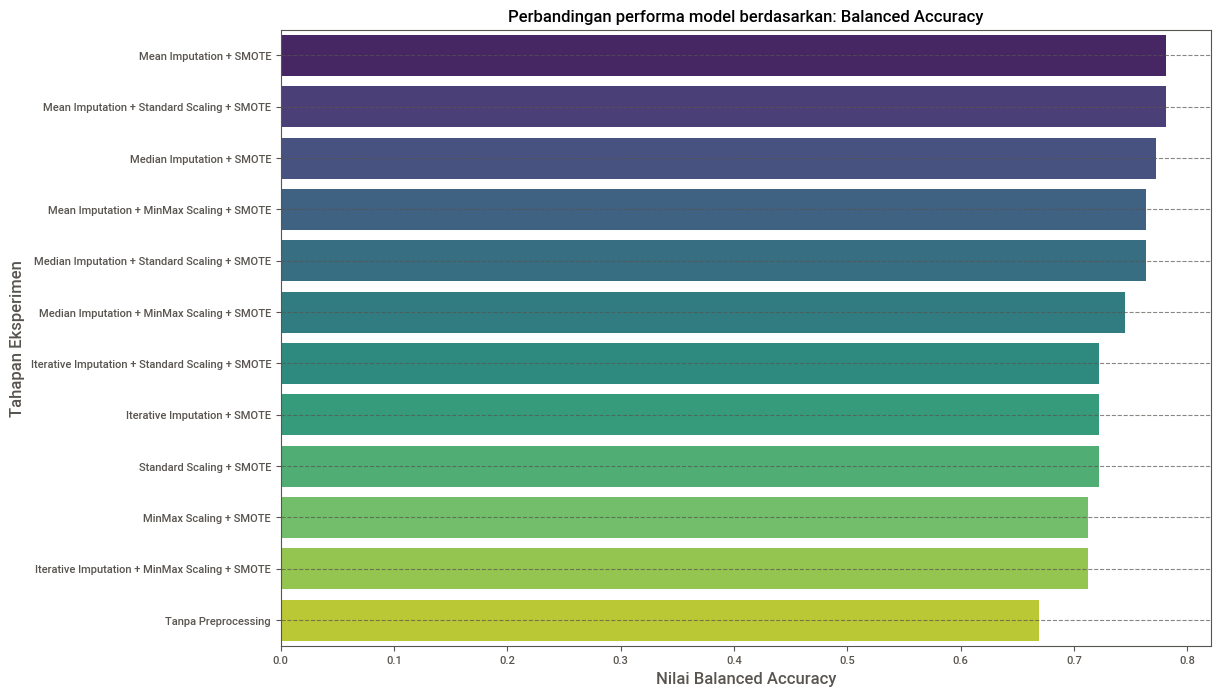

In [ ]:
plt.figure(figsize=(12, 8))

data_sorted = results.sort_values('Balanced Accuracy', ascending=False)
sns.barplot(x='Balanced Accuracy', y='Eksperimen', data=data_sorted, palette='viridis')

plt.title('Perbandingan performa model berdasarkan: Balanced Accuracy')
plt.xlabel('Nilai Balanced Accuracy', fontsize=12)
plt.ylabel('Tahapan Eksperimen', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



/tmp/ipykernel_545/2138200597.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Recall', y='Eksperimen', data=data_sorted, palette='magma')


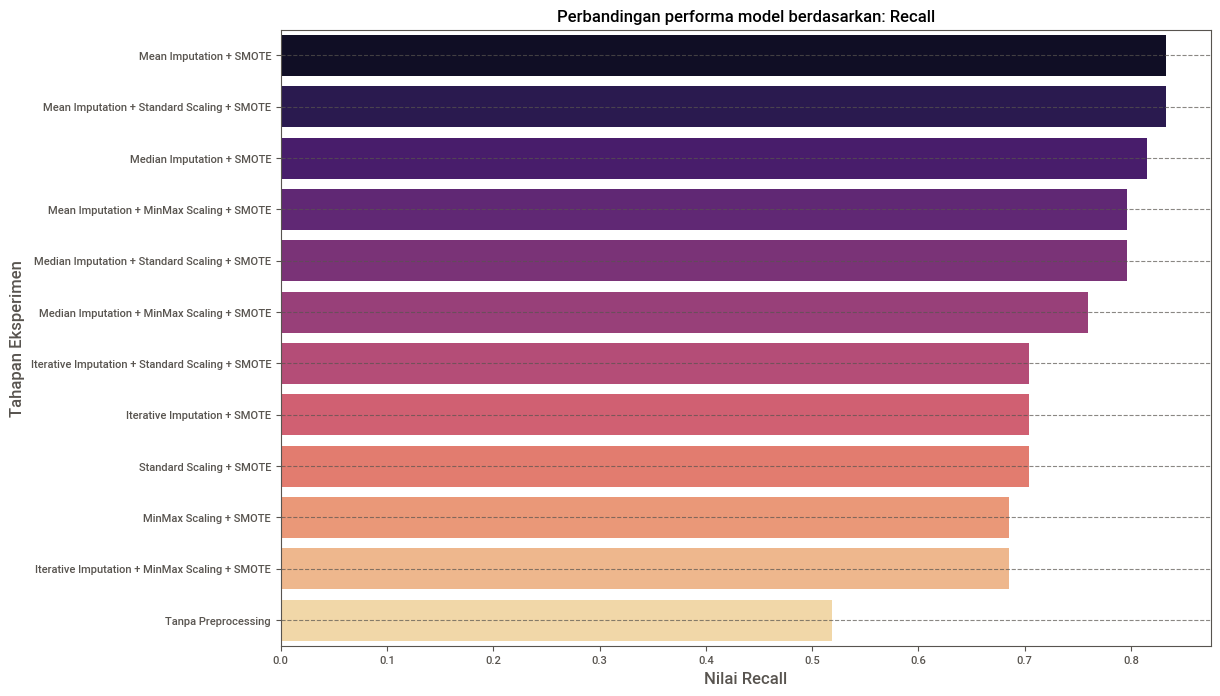

In [ ]:
plt.figure(figsize=(12, 8))

data_sorted = results.sort_values('Recall', ascending=False)
sns.barplot(x='Recall', y='Eksperimen', data=data_sorted, palette='magma')

plt.title('Perbandingan performa model berdasarkan: Recall')
plt.xlabel('Nilai Recall', fontsize=12)
plt.ylabel('Tahapan Eksperimen', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



/tmp/ipykernel_545/986959536.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='F1 Score', y='Eksperimen', data=data_sorted, palette='crest')


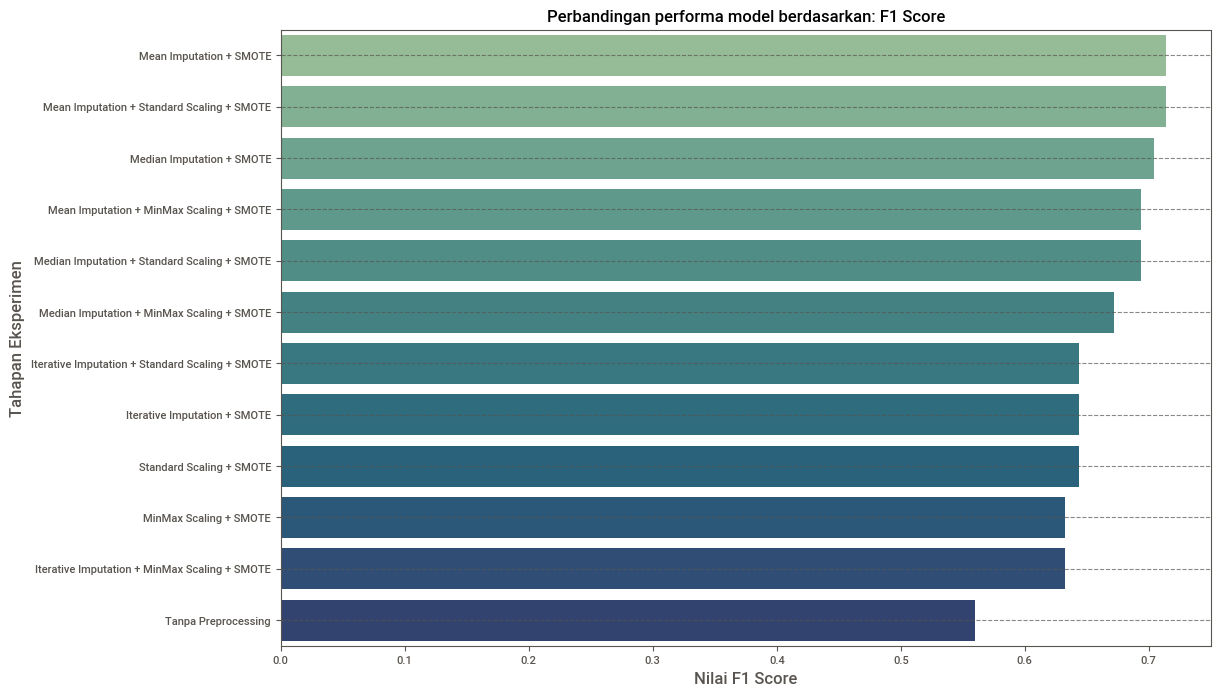

In [ ]:
plt.figure(figsize=(12, 8))

data_sorted = results.sort_values('F1 Score', ascending=False)
sns.barplot(x='F1 Score', y='Eksperimen', data=data_sorted, palette='crest')

plt.title('Perbandingan performa model berdasarkan: F1 Score')
plt.xlabel('Nilai F1 Score', fontsize=12)
plt.ylabel('Tahapan Eksperimen', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



# KESIMPULAN

Dalam dataset ini yang menjadi tolak ukur adalah metrik recall karena di dataset ini berada dalam domain medis. Recall  menghitung seberapa banyak pasien diabetes yang berhasil ditemukan oleh model dari total seluruh pasien diabetes yang ada

$$\text{Recall} = \frac{\text{True Positive (Terdeteksi Diabetes Benar)}}{\text{True Positive} + \text{False Negative (Menderita Diabetes tapi Lolos)}}$$


> Metode Imputasi Terbaik adalah Mean Imputation:
Pengisian nilai medis yang hilang menggunakan Mean Imputation (+ SMOTE) menghasilkan performa tertinggi dibandingkan metode Median maupun Iterative Imputation (MICE)

> SMOTE Terbukti Sangat Efektif
Meningkatkan Sensitivitas (Recall).
Penerapan SMOTE pada data latih berhasil meningkatkan kemampuan model dalam mendeteksi pasien diabetes secara drastis dari 51.85% (tanpa preprocessing) menjadi 83.33%.

> Metode Scaling Tidak Berdampak Signifikan pada Logistic Regression.
Penambahan Standard Scaling maupun MinMax Scaling tidak memberikan peningkatan kinerja yang berarti (bahkan nilainya identik dengan tanpa scaling). Hal ini terjadi karena Logistic Regression adalah model linier yang secara otomatis menyesuaikan bobot fiturnya.